
<div align="center">

<img src="https://capsule-render.vercel.app/api?type=waving&color=0:050B18,50:0B3D91,100:123B60&height=190&section=header&text=Luis%20Barahona&fontSize=42&fontColor=FFFFFF&fontAlignY=38&desc=DATA%20ENGINEERING%20%7C%20ARTIFICIAL%20INTELLIGENCE%20%7C%20DEVELOPER&descAlignY=62&descSize=14" width="50%" alt="Luis Barahona MX- Data Engineering and AI">

<img src="https://readme-typing-svg.demolab.com?font=Fira+Code&weight=500&size=17&duration=3500&pause=1200&color=38BDF8&center=true&vCenter=true&width=600&lines=Python+%7C+SQL+%7C+Data+Engineering;Artificial+Intelligence+%7C+Machine+Learning;Data+Science+%7C+Cloud+Computing;Building+Technology+for+the+Future" alt="Technical expertise">

</div>

---
<div align="center">
### Professional Profile

I am a Mexican Data Engineer and a 2026 graduate of Universidad del Caribe, passionate about technology, innovation, and continuous learning.
Beyond technical expertise, I value communication, teamwork, collaboration, and building meaningful connections with others. I believe that every person offers an opportunity to learn something new, and I am always motivated to share knowledge, explore new ideas, and grow both personally and professionally.

---

<div align="center">

<img src="https://skillicons.dev/icons?i=python,mysql,postgres,git,github,react,firebase,linux,docker,vscode&theme=dark" alt="Technical skills">


<strong>Data Engineering ·  Data Analytics · Data science · Artificial Intelligence · Machine Learning · Data Analytics · Developer</strong>

</div>

---
<div align="center">

| Platform | Contact |
|:---|:---|
| Email | [190300395@ucaribe.edu.mx](mailto:190300395@ucaribe.edu.mx) |
| GitHub | [github.com/LuisBarahonaMX](https://github.com/LuisBarahonaMX) |
| LinkedIn | [linkedin.com/in/luis-barahona-mx](https://www.linkedin.com/in/luis-barahona-mx/) |
| Instagram | [@luisbarahonamx](https://www.instagram.com/luisbarahonamx/) |
| X | [@luisbarahonaMX](https://x.com/luisbarahonaMX) |
| Website | [SIKO AI Platform](https://sikoai.web.app/) |
</div>



In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Introducción

En este documento definimos diferentes conceptos relacionados con la **transitabilidad** a lo largo de un grafo.

A partir de un grafo cualquiera, buscamos responder preguntas como las siguientes:

* ¿Cuál es el camino más corto entre dos vértices?
* ¿Se puede construir una ruta que use cada arista del grafo exactamente una vez?
* ¿Cuál es el camino más corto que pasa al menos una vez por cada nodo y vuelve al nodo inicial?

Estas (y otras) preguntas son relevantes en aplicaciones como:

1. **Redes de Telecomunicaciones:** La transitabilidad es clave en la transmisión de datos entre nodos de una red. Preguntas sobre caminos y rutas ayudan a determinar rutas de menor latencia o caminos alternativos en caso de fallos.
Los circuitos pueden analizarse para gestionar la redundancia en las redes, asegurando que haya caminos alternativos en caso de caídas.


2. **Logística y Transporte**: En planificación de rutas para entregas, se utilizan conceptos de caminos y rutas para optimizar la entrega de paquetes y minimizar el tiempo o la distancia recorrida.
En el caso de redes ferroviarias o rutas de autobuses, los caminos cerrados o circuitos permiten organizar rutas de ida y vuelta sin repetición excesiva de trayectos.


3. **Análisis de Redes Sociales:**, En redes sociales los caminos y circuitos pueden usarse para detectar comunidades o grupos de personas altamente conectados.
Los caminos cerrados permiten estudiar la influencia y conectividad entre nodos, como en la identificación de "circuitos de retroalimentación" que muestran cómo la información recircula en un grupo social.

4. **Biología Computacional:** En biología, especialmente en el estudio de redes metabólicas o de proteínas, las rutas y caminos permiten entender interacciones biológicas como cadenas de reacciones químicas o interacciones entre proteínas.
Los circuitos en redes de genes ayudan a comprender cómo ciertos genes se activan mutuamente en ciclos, permitiendo la regulación de procesos biológicos.


5. **Robótica y Drones:** Para los robots móviles y drones, encontrar caminos óptimos entre puntos de una red es esencial para la planificación de rutas en ambientes conocidos (mapas de grafos) o exploración de nuevas áreas.
Los caminos cerrados permiten la patrullaje de zonas o la vigilancia de perímetros, asegurando cobertura completa del área sin repeticiones innecesarias.


6. **Optimización en Redes Eléctricas:** Las preguntas sobre caminos y circuitos también se aplican en el diseño y análisis de redes eléctricas, asegurando que la energía pueda ser transmitida eficientemente desde estaciones generadoras a los consumidores y detectando la redundancia para mantener la estabilidad del sistema.



## Ejemplo

Emplearemos el siguiente grafo como referencia para definir los conceptos de:

* Camino.
* Ruta.
* Camino cerrado.
* Circuito.

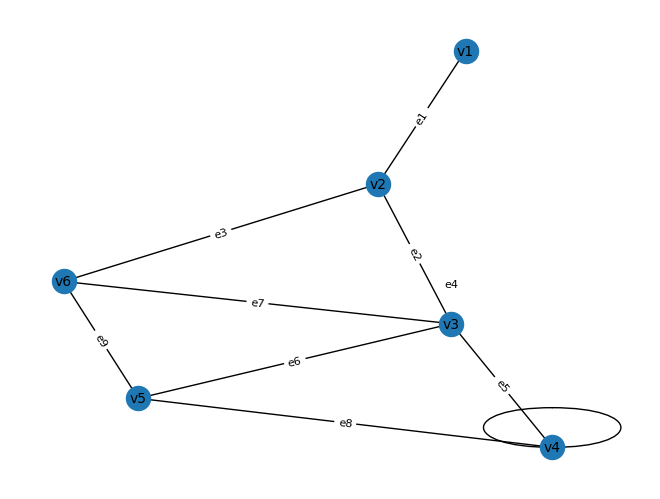

In [ ]:
G = nx.Graph()

G.add_nodes_from(["v1", "v2", "v3", "v4", "v5", "v6"])
G.add_edges_from([("v1","v2"),
                  ("v2","v3"), ("v2","v6"),
                  ("v3","v4"), ("v3","v5"), ("v3","v6"),
                  ("v4","v5"), ("v4","v4"),
                  ("v5","v6")
                  ])

pos = nx.spring_layout(G)

e_labs={("v1","v2"): "e1",("v2","v3"): "e2", ("v2","v6"): "e3", ("v3","v3"): "e4", ("v3","v4"): "e5", ("v3","v5"): "e6", ("v3","v6"): "e7",  ("v4","v5"): "e8",("v5","v6"): "e9"}

nx.draw(G, pos)
nx.draw_networkx_edge_labels(G, pos, e_labs, font_size=8)
nx.draw_networkx_labels(G, pos, font_size=10)
plt.show()

# Camino

Un camino entre una pareja de vértices (nodos) $v$ y $w$ una secuencia de vértices y aristas adyacentes que inicia en $v$ y termina en $w$.

Por ejemplo, la siguiente secuencia es un camino entre $v_1$ y $v_3$:

$$\color{red}{v_1}e_1v_2e_2\color{red}{v_3}$$

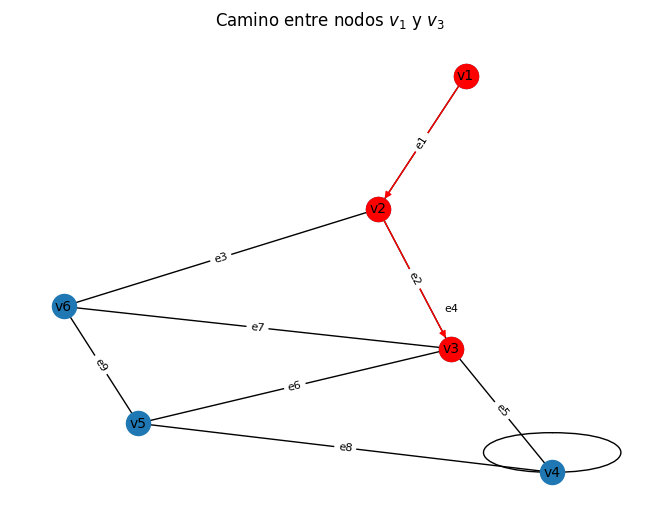

In [ ]:
# Ejemplo de un camino
n = ["v1", "v2", "v3"]
walk = nx.DiGraph()
walk.add_nodes_from(n)
walk.add_edge("v1","v2")
walk.add_edge("v2","v3")

nx.draw(G, pos)
nx.draw(walk, pos, node_color = 'r', edge_color="r")
nx.draw_networkx_edge_labels(G, pos, e_labs, font_size=8)
nx.draw_networkx_labels(G, pos, font_size=10)
plt.title("Camino entre nodos $v_1$ y $v_3$")
plt.show()


**<font color="red">Identifica otros caminos en el grafo que unan a los nodos $v_1$ y $v_3$</font>**

Otro ejemplo de camino sobre el misma grafo es el que une al vértice $v_4$ y al $v_5$

$$\color{red}{v_4}e_5v_3e_6v_5e_9v_6e_7v_3e_6\color{red}{v_5}$$

**Observa que en este camino repetimos vértices y aristas.**



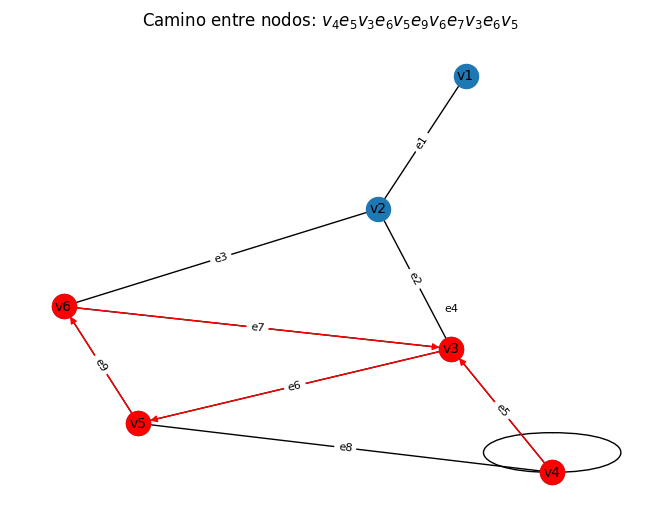

In [ ]:
# Ejemplo de un camino
n = ["v3", "v4", "v5","v6"]
walk = nx.DiGraph()
walk.add_nodes_from(n)
walk.add_edges_from([("v4","v3"),("v3","v5"), ("v5","v6"), ("v6","v3")])

nx.draw(G, pos)
nx.draw(walk, pos, node_color = 'r', edge_color="r")
nx.draw_networkx_edge_labels(G, pos, e_labs, font_size=8)
nx.draw_networkx_labels(G, pos, font_size=10)
plt.title("Camino entre nodos: $v_4e_5v_3e_6v_5e_9v_6e_7v_3e_6v_5$")
plt.show()


<font color="red">Actividad</font>

Dibuja un par de caminos sobre el grafo, diferentes, que unan los vértices $v_2$ y $v_4$.

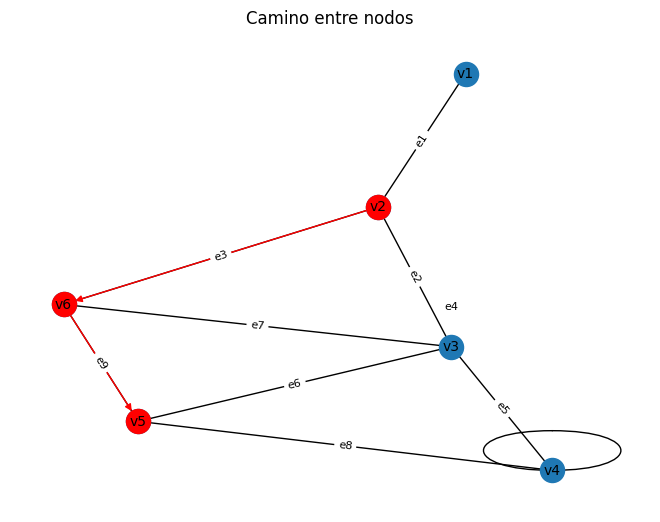

In [ ]:
# Ejemplo de un camino
n = ["v2", "v5","v6"]
walk = nx.DiGraph()
walk.add_nodes_from(n)
walk.add_edges_from([("v2","v6"),("v6","v5")])

nx.draw(G, pos)
nx.draw(walk, pos, node_color = 'r', edge_color="r")
nx.draw_networkx_edge_labels(G, pos, e_labs, font_size=8)
nx.draw_networkx_labels(G, pos, font_size=10)
plt.title("Camino entre nodos")
plt.show()


In [ ]:
# Ejemplo de un camino
n = ["v3", "v4", "v5","v6"]
walk = nx.DiGraph()
walk.add_nodes_from(n)
walk.add_edges_from([("v3","v6"),("v6","v5"), ("v5","v4")])

nx.draw(G, pos)
nx.draw(walk, pos, node_color = 'r', edge_color="r")
nx.draw_networkx_edge_labels(G, pos, e_labs, font_size=8)
nx.draw_networkx_labels(G, pos, font_size=10)
plt.title("Camino entre nodos")
plt.show()


# Ruta

Una *ruta* es un camino entre dos vértices en el que **no se repiten vértices ni aristas**.

Los siguientes son ejemplos de rutas sobre una gráfica.


## Ejemplo 1

Considera el siguiente camino entre los vértices $v_4$ y $v_6$:

$$\color{red}{v_4}e_5v_3e_6v_5e_9\color{red}{v_6}$$

**Este camino es una ruta** pues no se repiten aristas ni vértices.

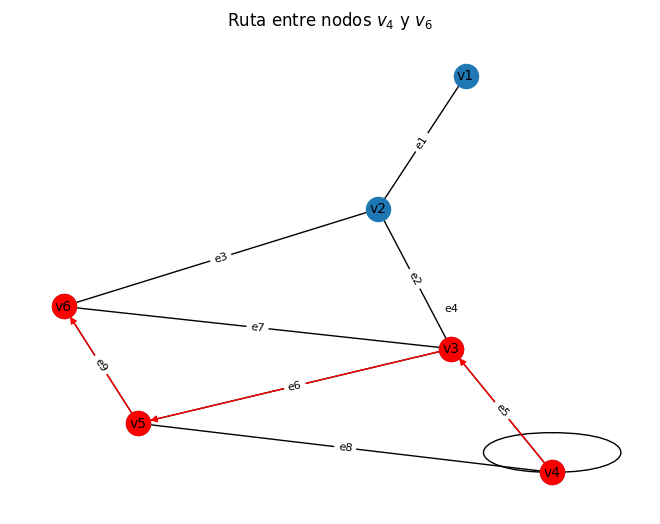

In [ ]:
# Ejemplo de una ruta

n = ["v3", "v4", "v5", "v6"]
path = nx.DiGraph()
path.add_nodes_from(n)
path.add_edges_from([("v4","v3"),("v3","v5"), ("v5","v6")])

nx.draw(G, pos)
nx.draw(path, pos, node_color = 'r', edge_color="r")
nx.draw_networkx_edge_labels(G, pos, e_labs, font_size=8)
nx.draw_networkx_labels(G, pos, font_size=10)
#nx.draw_networkx_labels(path, pos, font_size=10)
plt.title("Ruta entre nodos $v_4$ y $v_6$")
plt.show()


## Ejemplo 2

La siguiente ruta une a los vértices $v_2$ con $v_5$

$$\color{red}{v_2}e_3v_6e_9\color{red}{v_5}$$

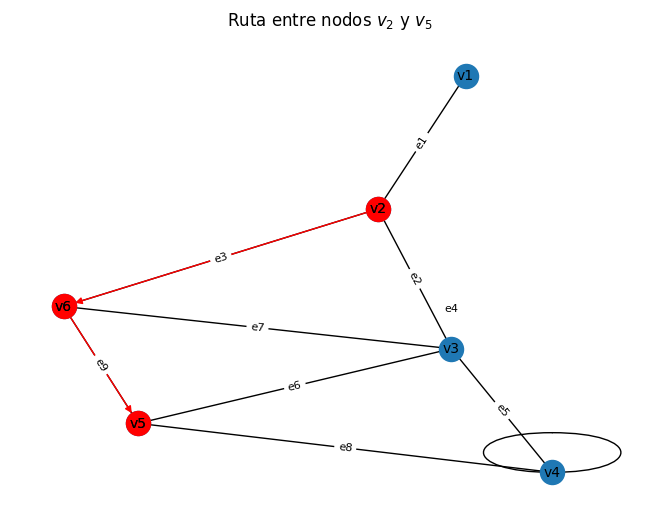

In [ ]:
# Ejemplo de una ruta
n = ["v2", "v6", "v5"]
walk = nx.DiGraph()
walk.add_nodes_from(n)
walk.add_edges_from([("v2","v6"),("v6","v5")])

nx.draw(G, pos)
nx.draw(walk, pos, node_color = 'r', edge_color="r")
nx.draw_networkx_edge_labels(G, pos, e_labs, font_size=8)
nx.draw_networkx_labels(G, pos, font_size=10)
nx.draw_networkx_labels(walk, pos, font_size=10)
plt.title("Ruta entre nodos $v_2$ y $v_5$")
plt.show()

<font color="red">Actividad</font>

Dibuja un par de rutas sobre la gráfica.

# Camino cerrado

Un camino cerrado es un camino que inicia y termina en el mismo vértice.

El siguiente es un ejemplo de un camino cerrado:

$$\color{red}{v_2}e_3v_6e_7v_3e_2\color{red}{v_2}$$

Por definición, un camino cerrado no puede ser una ruta.

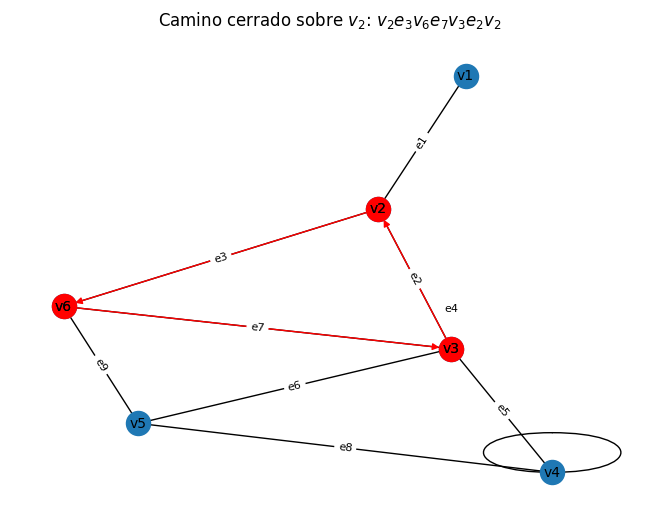

In [ ]:
# Ejemplo de un camino cerrado
n = ["v2", "v6", "v3"]
walk = nx.DiGraph()
walk.add_nodes_from(n)
walk.add_edges_from([("v2","v6"),("v6","v3"), ("v3","v2")])

nx.draw(G, pos)
nx.draw(walk, pos, node_color = 'r', edge_color="r")
nx.draw_networkx_edge_labels(G, pos, e_labs, font_size=8)
nx.draw_networkx_labels(G, pos, font_size=10)
nx.draw_networkx_labels(walk, pos, font_size=10)
plt.title("Camino cerrado sobre $v_2$: $v_2e_3v_6e_7v_3e_2v_2$")
plt.show()

Otro camino cerrado es el siguente:

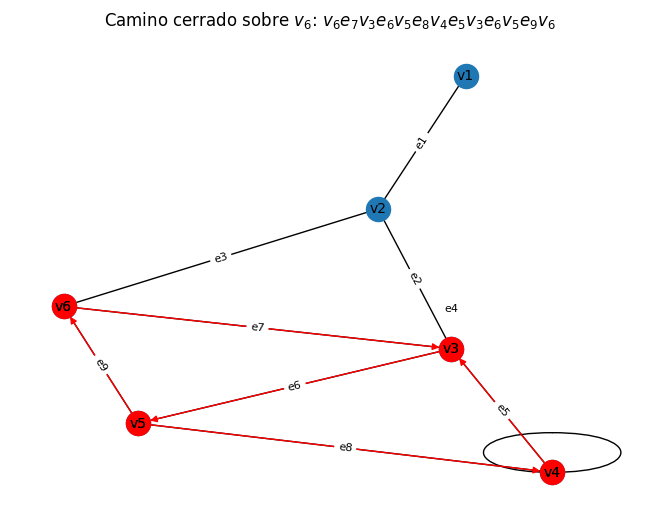

In [ ]:
# Ejemplo de un camino cerrado
n = ["v6", "v3", "v4", "v5"]
walk = nx.DiGraph()
walk.add_nodes_from(n)
walk.add_edges_from([("v6","v3"),("v3","v5"), ("v5","v4"), ("v4","v3"), ("v3","v5"), ("v5","v6")])

nx.draw(G, pos)
nx.draw(walk, pos, node_color = 'r', edge_color="r")
nx.draw_networkx_edge_labels(G, pos, e_labs, font_size=8)
nx.draw_networkx_labels(G, pos, font_size=10)
nx.draw_networkx_labels(walk, pos, font_size=10)
plt.title("Camino cerrado sobre $v_6$: $v_6e_7v_3e_6v_5e_8v_4e_5v_3e_6v_5e_9v_6$")
plt.show()

Observa que en este camino cerrado se repiten vértices y aristas.

<font color="red">Actividad</font>

Dibuja un par de caminos cerrados sobre la gráfica.

# Circuito

Un circuito es un **camino cerrado**, que contiene por lo menos una arista y que no contiene aristas repetidas (observa que no se indica ninguna restricción sobre los nodos del camino).

En las siguientes celdas se muestran algunos circuitos.

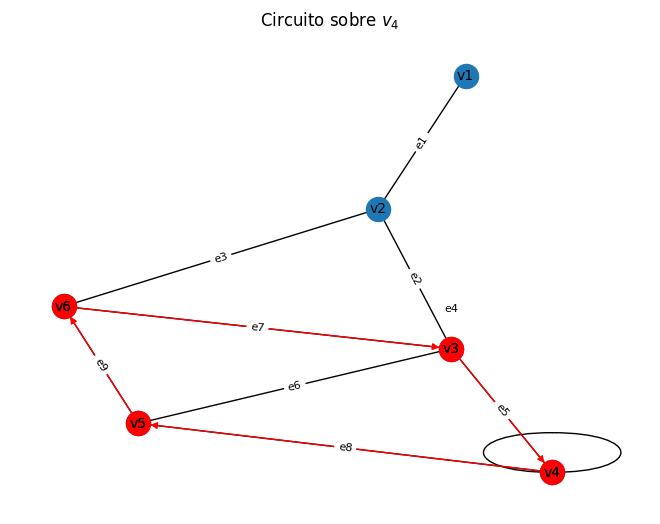

In [ ]:
# Ejemplo de un circuito
n = ["v4", "v5", "v6", "v3"]
walk = nx.DiGraph()
walk.add_nodes_from(n)
walk.add_edges_from([("v4","v5"),("v5","v6"), ("v6","v3"), ("v3","v4")])

nx.draw(G, pos)
nx.draw(walk, pos, node_color = 'r', edge_color="r")
nx.draw_networkx_edge_labels(G, pos, e_labs, font_size=8)
nx.draw_networkx_labels(G, pos, font_size=10)
nx.draw_networkx_labels(walk, pos, font_size=10)
plt.title("Circuito sobre $v_4$")
plt.show()

<font color="red">Actividad</font>

Considera el siguiente grafo:

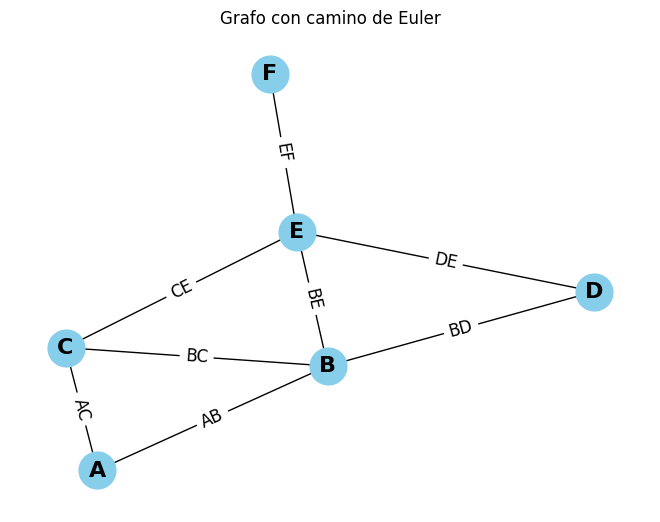

In [ ]:
# Crea un grafo no dirigido
G = nx.Graph()

# Agregar 6 nodos
G.add_nodes_from(["A", "B", "C", "D", "E", "F"])

# Agrega aristas
G.add_edges_from([("A", "B"), ("A", "C"), ("B", "C"), ("B", "D"), ("B", "E"), ("C", "E"), ("D", "E"), ("E", "F")])

# Dibujar el grafo
pos = nx.spring_layout(G)
nx.draw(G, pos, with_labels=True, node_color='skyblue', node_size=700, font_size=16, font_weight='bold')
nx.draw_networkx_edge_labels(G, pos, edge_labels={(u, v): f"{u}{v}" for u, v in G.edges()}, font_size=12)

# Mostrar el grafo
plt.title("Grafo con camino de Euler")
plt.show()


**Encuentra un camino que recorra todas las aristas, sin repetir una sola.**

¿Puedes encontrar un camino con las mismas características en el siguiente grafo?

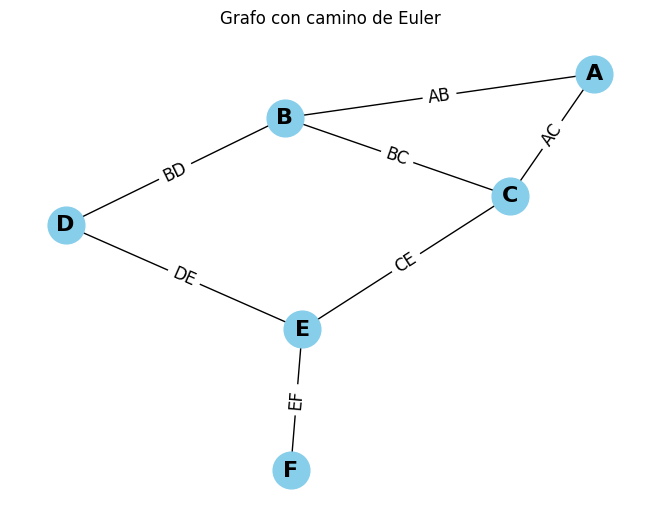

In [ ]:
# Crea un grafo no dirigido
G = nx.Graph()

# Agregar 6 nodos
G.add_nodes_from(["A", "B", "C", "D", "E", "F"])

# Agrega aristas
G.add_edges_from([("A", "B"), ("A", "C"), ("B", "C"), ("B", "D"), ("C", "E"), ("D", "E"), ("E", "F")])

# Dibujar el grafo
pos = nx.spring_layout(G)
nx.draw(G, pos, with_labels=True, node_color='skyblue', node_size=700, font_size=16, font_weight='bold')
nx.draw_networkx_edge_labels(G, pos, edge_labels={(u, v): f"{u}{v}" for u, v in G.edges()}, font_size=12)

# Mostrar el grafo
plt.title("Grafo con camino de Euler")
plt.show()
